#  From Forecasts to Inventory Decisions

##  Setup

In [5]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (12, 5), "axes.titlesize": 13, "axes.titleweight": "bold"})
pd.set_option("display.float_format", "{:,.2f}".format)

ROOT = Path("..")
PRED_PATH = ROOT / "data" / "processed" / "test_predictions.csv"     # created by notebook 02
CLEAN_PATH = ROOT / "data" / "processed" / "demand_clean.csv"        # created by notebook 01
FIG_DIR, REPORT_DIR = ROOT / "reports" / "figures", ROOT / "reports"
FIG_DIR.mkdir(parents=True, exist_ok=True)

SERVICE_LEVEL = 0.95                       # target: cover demand on 95% of days
CAL_END = pd.Timestamp("2023-12-01")       # calibrate buffers before this date, evaluate from this date


def save_fig(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## Load forecasts and observed inventory

In [6]:
pred = pd.read_csv(PRED_PATH, parse_dates=["date"])
stock = pd.read_csv(CLEAN_PATH, parse_dates=["date"], usecols=["date", "store_id", "product_id", "inventory_level"])
stock["series_id"] = stock["store_id"].astype(str) + "_" + stock["product_id"].astype(str)

df = pred.merge(stock[["date", "series_id", "inventory_level"]], on=["date", "series_id"], how="left", validate="one_to_one")
assert df["inventory_level"].notna().all(), "inventory_level could not be matched"

MODELS = [c.removeprefix("pred_") for c in df.columns if c.startswith("pred_")]
print("Models:", MODELS)

cal = df[df["date"] < CAL_END]
ev = df[df["date"] >= CAL_END]
print(f"Calibration: {cal['date'].min().date()} → {cal['date'].max().date()} ({len(cal):,} rows, {cal['epidemic'].mean() * 100:.0f}% epidemic days)")
print(f"Evaluation : {ev['date'].min().date()} → {ev['date'].max().date()} ({len(ev):,} rows, {ev['epidemic'].mean() * 100:.0f}% epidemic days)")

Models: ['Naive-7', 'Rolling mean (7d)', 'Series mean (train)', 'Ridge (epidemic known)', 'XGBoost (epidemic unknown)', 'XGBoost (epidemic known)']
Calibration: 2023-10-01 → 2023-11-30 (6,100 rows, 30% epidemic days)
Evaluation : 2023-12-01 → 2024-01-30 (6,100 rows, 21% epidemic days)


## Stock targets and service level

In [7]:
def buffers(frame, model, q):
    err = frame["demand"] - frame[f"pred_{model}"]
    return err.groupby(frame["category"]).quantile(q)


def target_stock(frame, model, buf):
    return np.maximum(frame[f"pred_{model}"] + frame["category"].map(buf), 0)


def policy_metrics(frame, stock_level):
    excess = np.maximum(stock_level - frame["demand"], 0)
    short = np.maximum(frame["demand"] - stock_level, 0)
    return {"service_level_%": (stock_level >= frame["demand"]).mean() * 100,
            "avg_stock": stock_level.mean(),
            "avg_excess": excess.mean(),
            "excess_%_of_demand": excess.sum() / frame["demand"].sum() * 100,
            "unmet_%_of_demand": short.sum() / frame["demand"].sum() * 100}


rows = {m: policy_metrics(ev, target_stock(ev, m, buffers(cal, m, SERVICE_LEVEL))) for m in MODELS}
policy = pd.DataFrame(rows).T.sort_values("avg_excess")
policy["excess_reduction_vs_naive_%"] = (1 - policy["avg_excess"] / policy.loc["Naive-7", "avg_excess"]) * 100
policy

,service_level_%,avg_stock,avg_excess,excess_%_of_demand,unmet_%_of_demand,excess_reduction_vs_naive_%
XGBoost (epidemic unknown),90.05,115.03,13.94,13.70,0.63,83.96
XGBoost (epidemic known),93.90,116.00,14.63,14.38,0.35,83.17
Ridge (epidemic known),93.74,155.52,54.94,54.01,1.14,36.77
Series mean (train),92.30,165.65,65.72,64.60,1.77,24.37
Rolling mean (7d),93.67,177.66,77.51,76.20,1.55,10.80
Naive-7,93.62,186.90,86.89,85.42,1.69,0.00


## The service-level / excess-stock trade-off

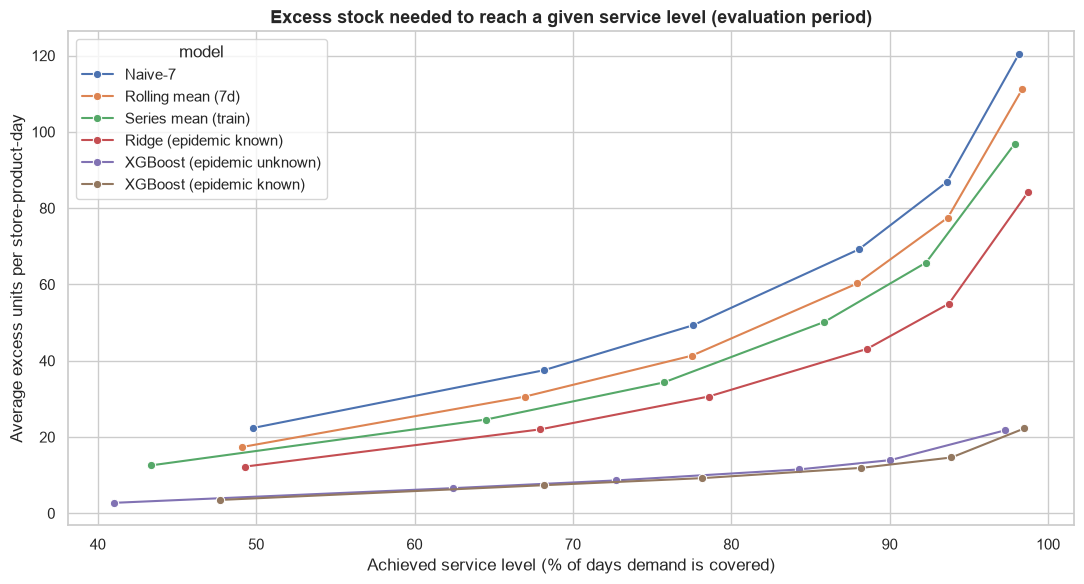

In [8]:
levels = [0.5, 0.7, 0.8, 0.9, 0.95, 0.99]
curve = pd.DataFrame([
    {"model": m, "target_level": q, **policy_metrics(ev, target_stock(ev, m, buffers(cal, m, q)))}
    for m in MODELS for q in levels
])

fig, ax = plt.subplots(figsize=(11, 6))
sns.lineplot(data=curve, x="service_level_%", y="avg_excess", hue="model", marker="o", ax=ax)
ax.set(title="Excess stock needed to reach a given service level (evaluation period)",
       xlabel="Achieved service level (% of days demand is covered)", ylabel="Average excess units per store-product-day")
save_fig("18_service_level_tradeoff")
plt.show()

## Where does the saving come from?

In [9]:
focus = ["Naive-7", "XGBoost (epidemic unknown)", "XGBoost (epidemic known)"]
ev_t = ev.copy()
for m in focus:
    ev_t[f"tgt_{m}"] = target_stock(ev_t, m, buffers(cal, m, SERVICE_LEVEL))


def breakdown(by):
    out = {}
    for m in focus:
        g = ev_t.groupby(by)
        out[(m, "excess")] = g.apply(lambda d: np.maximum(d[f"tgt_{m}"] - d["demand"], 0).mean(), include_groups=False)
        out[(m, "service_%")] = g.apply(lambda d: (d[f"tgt_{m}"] >= d["demand"]).mean() * 100, include_groups=False)
    return pd.DataFrame(out)


print("By category"); display(breakdown("category").round(1))
print("By epidemic status (0 = normal, 1 = epidemic)"); display(breakdown("epidemic").round(1))

By category


Naive-7           XGBoost (epidemic unknown)            \
             excess service_%                     excess service_%   
category                                                             
Clothing      89.40     92.60                      16.00     93.00   
Electronics   81.50     93.60                      14.50     92.80   
Furniture     68.90     94.00                      10.10     87.30   
Groceries     94.10     93.80                      15.40     90.90   
Toys          91.20     93.80                      11.90     85.20   

            XGBoost (epidemic known)            
                              excess service_%  
category                                        
Clothing                       14.90     92.20  
Electronics                    15.10     95.40  
Furniture                      11.50     94.40  
Groceries                      16.40     94.10  
Toys                           13.00     93.40

By epidemic status (0 = normal, 1 = epidemic)


Naive-7           XGBoost (epidemic unknown)            \
          excess service_%                     excess service_%   
epidemic                                                          
0          80.90     92.30                      13.30     88.20   
1         108.90     98.50                      16.10     96.80   

         XGBoost (epidemic known)            
                           excess service_%  
epidemic                                     
0                           14.60     93.80  
1                           14.60     94.50

## Indicative comparison with the stock the retailer actually held

In [10]:
m = "XGBoost (epidemic unknown)"
compare = pd.DataFrame({
    "Observed inventory": policy_metrics(ev, ev["inventory_level"]),
    f"Forecast-based target ({m}, {SERVICE_LEVEL:.0%})": policy_metrics(ev, target_stock(ev, m, buffers(cal, m, SERVICE_LEVEL))),
}).T
compare

,service_level_%,avg_stock,avg_excess,excess_%_of_demand,unmet_%_of_demand
Observed inventory,86.34,298.49,203.08,199.63,6.22
"Forecast-based target (XGBoost (epidemic unknown), 95%)",90.05,115.03,13.94,13.70,0.63


**The forecast-based policy using XGBoost (epidemic unknown) improves the service level from 86.34% to 90.05%, while reducing average stock from 298.49 to 115.03 units. It also reduces average excess inventory from 203.08 to 13.94 units, demonstrating a substantial improvement in inventory efficiency with fewer unmet demand units.

##  Save results

In [11]:
policy.round(3).to_csv(REPORT_DIR / "inventory_policy_summary.csv")
compare.round(3).to_csv(REPORT_DIR / "inventory_vs_observed.csv")
print("Saved reports/inventory_policy_summary.csv and reports/inventory_vs_observed.csv")

Saved reports/inventory_policy_summary.csv and reports/inventory_vs_observed.csv
